In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Load beginning-of-term model
early_model = joblib.load(
    "../artifacts/beginning_term_model.pkl"
)

early_preprocessor = joblib.load(
    "../artifacts/beginning_term_preprocessor.pkl"
)

early_metrics = joblib.load(
    "../artifacts/beginning_term_model_metrics.pkl"
)

# Load processed data
processed_data = joblib.load(
    "../artifacts/processed_data.pkl"
)

# Load original dataset
df_original = pd.read_csv(
    "../dataset/student-mat.csv",
    sep=";"
)

print("Day 06 Environment Setup Completed")
print("-----------------------------------")
print("Model:", type(early_model).__name__)
print("Dataset shape:", df_original.shape)
print("Saved model MAE:", round(early_metrics["MAE"], 3))
print("Saved model R2:", round(early_metrics["R2"], 3))

Day 06 Environment Setup Completed
-----------------------------------
Model: RandomForestRegressor
Dataset shape: (395, 33)
Saved model MAE: 3.342
Saved model R2: 0.141


In [2]:
from sklearn.model_selection import train_test_split

# Define beginning-of-term features
excluded_features = ["G1", "G2", "G3", "absences"]

early_features = [
    col for col in df_original.columns
    if col not in excluded_features
]

X_early = df_original[early_features]
y_early = df_original["G3"]

# Recreate the original train-test split
X_train_early, X_test_early, y_train_early, y_test_early = train_test_split(
    X_early,
    y_early,
    test_size=0.2,
    random_state=42
)

# Transform test data using the saved preprocessor
X_test_processed = early_preprocessor.transform(X_test_early)

# Generate predictions
y_pred = early_model.predict(X_test_processed)

print("Prediction Generation Completed")
print("--------------------------------")
print("Test records:", len(y_test_early))
print("Predictions:", len(y_pred))
print("Actual grades:", len(y_test_early))

print("\nFirst 10 predictions:")
display(pd.DataFrame({
    "Actual_Grade": y_test_early.iloc[:10].values,
    "Predicted_Grade": np.round(y_pred[:10], 2)
}))

Prediction Generation Completed
--------------------------------
Test records: 79
Predictions: 79
Actual grades: 79

First 10 predictions:


,Actual_Grade,Predicted_Grade
0,10,3.82
1,12,8.29
2,5,8.05
3,10,10.90
4,9,8.72
5,13,10.93
6,18,12.13
7,6,11.80
8,0,11.42
9,14,11.27


In [3]:
# Create prediction analysis DataFrame

prediction_analysis = pd.DataFrame({
    "Actual": y_test_early.values,
    "Predicted": y_pred
})

# Calculate errors
prediction_analysis["Error"] = (
    prediction_analysis["Actual"] -
    prediction_analysis["Predicted"]
)

prediction_analysis["Absolute_Error"] = (
    prediction_analysis["Error"].abs()
)

prediction_analysis["Error_Percentage"] = np.where(
    prediction_analysis["Actual"] != 0,
    (prediction_analysis["Absolute_Error"] /
     prediction_analysis["Actual"]) * 100,
    np.nan
)

print("Prediction Error Analysis")
print("-------------------------")

print("Mean Absolute Error:",
      round(prediction_analysis["Absolute_Error"].mean(), 3))

print("Maximum Absolute Error:",
      round(prediction_analysis["Absolute_Error"].max(), 3))

print("Minimum Absolute Error:",
      round(prediction_analysis["Absolute_Error"].min(), 3))

print("Mean Signed Error:",
      round(prediction_analysis["Error"].mean(), 3))

print("\nFirst 10 error records:")
display(prediction_analysis.head(10))

Prediction Error Analysis
-------------------------
Mean Absolute Error: 3.342
Maximum Absolute Error: 11.482
Minimum Absolute Error: 0.049
Mean Signed Error: 0.233

First 10 error records:


,Actual,Predicted,Error,Absolute_Error,Error_Percentage
0,10,3.818388,6.181612,6.181612,61.816122
1,12,8.288615,3.711385,3.711385,30.928209
2,5,8.045948,-3.045948,3.045948,60.918954
3,10,10.902145,-0.902145,0.902145,9.021453
4,9,8.715388,0.284612,0.284612,3.162352
5,13,10.934064,2.065936,2.065936,15.891819
6,18,12.125141,5.874859,5.874859,32.638106
7,6,11.800648,-5.800648,5.800648,96.677462
8,0,11.418097,-11.418097,11.418097,NaN
9,14,11.271329,2.728671,2.728671,19.490505


In [4]:
# Categorize prediction errors

def classify_error(error):
    if error <= 2:
        return "Close Prediction"
    elif error <= 5:
        return "Moderate Error"
    else:
        return "Large Error"

prediction_analysis["Error_Category"] = (
    prediction_analysis["Absolute_Error"].apply(classify_error)
)

# Count each category
error_counts = prediction_analysis["Error_Category"].value_counts()

print("Prediction Accuracy Categories")
print("-------------------------------")
display(error_counts.to_frame(name="Number of Students"))

print("\nPercentage Distribution:")
display(
    (error_counts / len(prediction_analysis) * 100)
    .round(2)
    .to_frame(name="Percentage")
)

Prediction Accuracy Categories
-------------------------------


,Number of Students
Error_Category,
Moderate Error,35
Close Prediction,26
Large Error,18



Percentage Distribution:


,Percentage
Error_Category,
Moderate Error,44.30
Close Prediction,32.91
Large Error,22.78


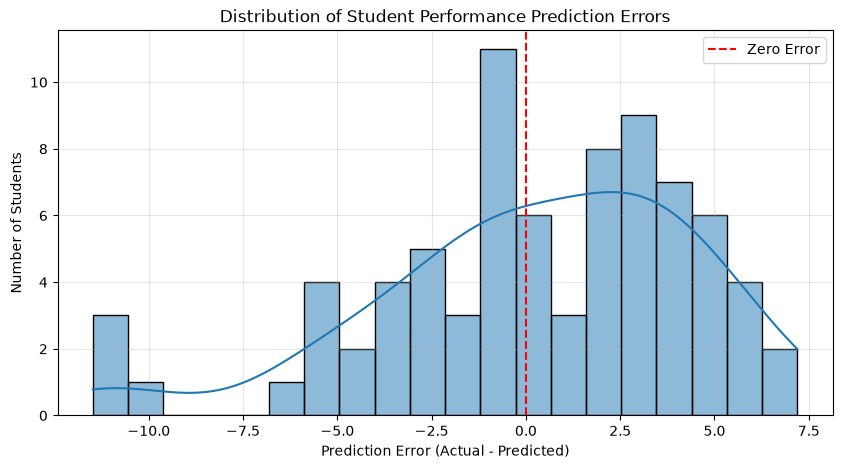

In [5]:
plt.figure(figsize=(10, 5))

sns.histplot(
    prediction_analysis["Error"],
    bins=20,
    kde=True
)

plt.axvline(
    0,
    color="red",
    linestyle="--",
    label="Zero Error"
)

plt.title("Distribution of Student Performance Prediction Errors")
plt.xlabel("Prediction Error (Actual - Predicted)")
plt.ylabel("Number of Students")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [6]:
# Group students by actual grade

grade_bins = [-1, 5, 10, 15, 20]

grade_labels = [
    "Low (0-5)",
    "Below Average (6-10)",
    "Above Average (11-15)",
    "High (16-20)"
]

prediction_analysis["Grade_Category"] = pd.cut(
    prediction_analysis["Actual"],
    bins=grade_bins,
    labels=grade_labels
)

# Calculate error metrics for each grade category

grade_error_analysis = (
    prediction_analysis
    .groupby("Grade_Category", observed=False)
    .agg(
        Student_Count=("Actual", "count"),
        Mean_Actual_Grade=("Actual", "mean"),
        Mean_Predicted_Grade=("Predicted", "mean"),
        MAE=("Absolute_Error", "mean"),
        Mean_Signed_Error=("Error", "mean")
    )
    .round(3)
)

print("Error Analysis by Actual Grade Category")
print("---------------------------------------")
display(grade_error_analysis)

Error Analysis by Actual Grade Category
---------------------------------------


,Student_Count,Mean_Actual_Grade,Mean_Predicted_Grade,MAE,Mean_Signed_Error
Grade_Category,,,,,
Low (0-5),9,2.222,8.708,6.485,-6.485
Below Average (6-10),29,8.483,9.931,2.870,-1.448
Above Average (11-15),31,13.355,11.261,2.212,2.093
High (16-20),10,17.100,11.712,5.388,5.388


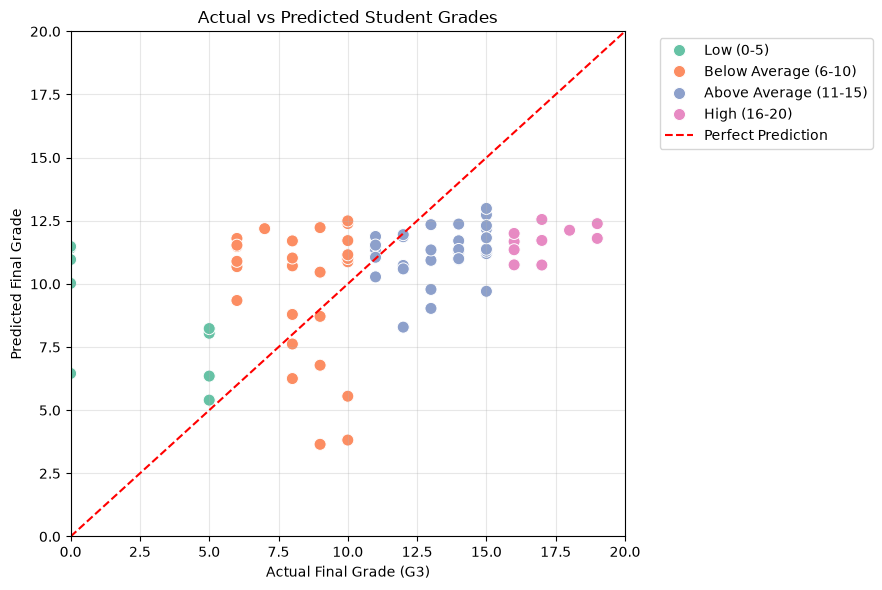

In [7]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=prediction_analysis["Actual"],
    y=prediction_analysis["Predicted"],
    hue=prediction_analysis["Grade_Category"],
    palette="Set2",
    s=75
)

# Ideal prediction line
plt.plot(
    [0, 20],
    [0, 20],
    color="red",
    linestyle="--",
    label="Perfect Prediction"
)

plt.xlim(0, 20)
plt.ylim(0, 20)

plt.title("Actual vs Predicted Student Grades")
plt.xlabel("Actual Final Grade (G3)")
plt.ylabel("Predicted Final Grade")

plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

In [8]:
# Extract transformed feature names
feature_names = early_preprocessor.get_feature_names_out()

# Extract feature importance
early_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": early_model.feature_importances_
})

# Sort by importance
early_importance_df = early_importance_df.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

print("Top 15 Important Features")
print("-------------------------")
display(early_importance_df.head(15))

Top 15 Important Features
-------------------------


,Feature,Importance
0,num__failures,0.283392
1,cat__guardian_other,0.056501
2,num__health,0.052156
3,num__goout,0.047868
4,num__Walc,0.039504
5,num__freetime,0.037151
6,num__studytime,0.036951
7,num__age,0.034673
8,num__Medu,0.029426
9,cat__Mjob_at_home,0.028963


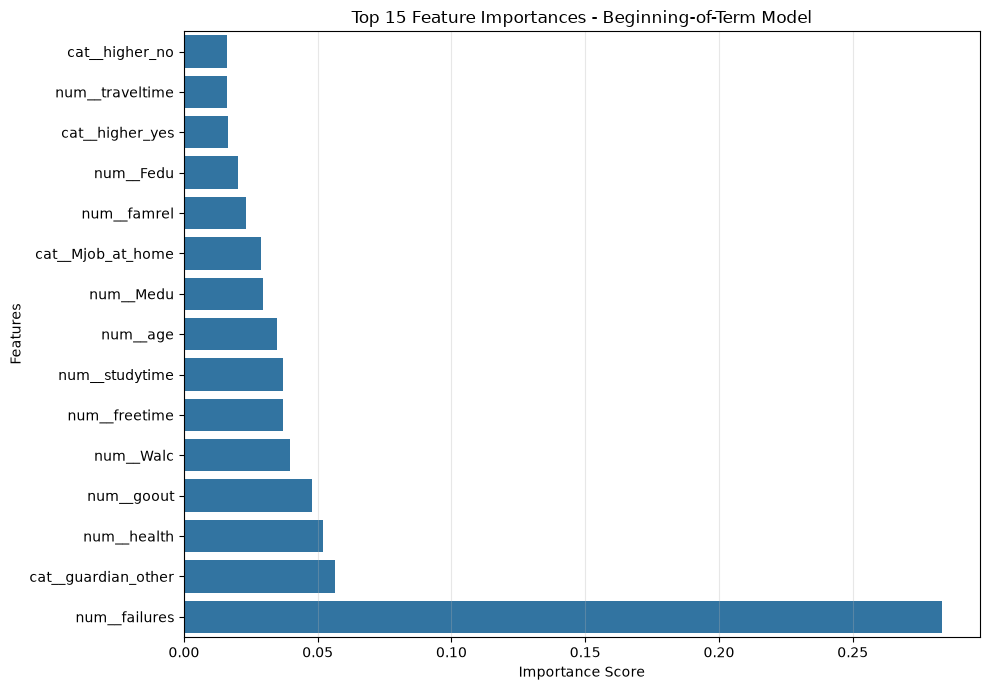

In [9]:
# Select top 15 features
top_15_importance = early_importance_df.head(15).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_15_importance,
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Feature Importances - Beginning-of-Term Model")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

In [13]:
# Load original preprocessing pipeline
preprocessor = joblib.load(
    "../artifacts/preprocessor.pkl"
)

# Verify
print("Original preprocessor loaded successfully.")
print("Original transformed features:",
      len(preprocessor.get_feature_names_out()))

print("Beginning-of-term transformed features:",
      len(early_preprocessor.get_feature_names_out()))

Original preprocessor loaded successfully.
Original transformed features: 56
Beginning-of-term transformed features: 55


In [14]:
# Original model feature importance
original_feature_names = preprocessor.get_feature_names_out()

original_importance_df = pd.DataFrame({
    "Feature": original_feature_names,
    "Original_Importance": original_model.feature_importances_
})

# Beginning-of-term model feature importance
early_importance_comparison = early_importance_df[
    ["Feature", "Importance"]
].rename(columns={
    "Importance": "Early_Importance"
})

# Compare common features
importance_comparison = pd.merge(
    original_importance_df,
    early_importance_comparison,
    on="Feature",
    how="inner"
)

# Calculate importance difference
importance_comparison["Importance_Change"] = (
    importance_comparison["Early_Importance"] -
    importance_comparison["Original_Importance"]
)

importance_comparison = importance_comparison.sort_values(
    by="Early_Importance",
    ascending=False
).reset_index(drop=True)

print("Feature Importance Comparison")
print("-----------------------------")
display(importance_comparison.head(15))

Feature Importance Comparison
-----------------------------


,Feature,Original_Importance,Early_Importance,Importance_Change
0,num__failures,0.241850,0.283392,0.041542
1,cat__guardian_other,0.016518,0.056501,0.039983
2,num__health,0.048028,0.052156,0.004128
3,num__goout,0.037610,0.047868,0.010258
4,num__Walc,0.017064,0.039504,0.022440
5,num__freetime,0.018140,0.037151,0.019011
6,num__studytime,0.026094,0.036951,0.010857
7,num__age,0.030746,0.034673,0.003926
8,num__Medu,0.021927,0.029426,0.007499
9,cat__Mjob_at_home,0.016795,0.028963,0.012167


In [12]:
# Load original Random Forest model
original_model = joblib.load(
    "../artifacts/student_performance_model.pkl"
)

print("Original model loaded successfully.")
print("Model:", type(original_model).__name__)
print("Number of features:", len(original_model.feature_importances_))

Original model loaded successfully.
Model: RandomForestRegressor
Number of features: 56


In [16]:
# Transform training and testing data
X_train_early_processed = early_preprocessor.transform(
    X_train_early
)

X_test_processed = early_preprocessor.transform(
    X_test_early
)

print("Processed datasets recreated successfully.")
print("Training shape:", X_train_early_processed.shape)
print("Testing shape:", X_test_processed.shape)

Processed datasets recreated successfully.
Training shape: (316, 55)
Testing shape: (79, 55)


In [17]:
# Identify the failures feature index
early_feature_names = early_preprocessor.get_feature_names_out()

failures_index = list(early_feature_names).index(
    "num__failures"
)

# Remove failures from training and testing data
X_train_no_failures = np.delete(
    X_train_early_processed,
    failures_index,
    axis=1
)

X_test_no_failures = np.delete(
    X_test_processed,
    failures_index,
    axis=1
)

print("Dataset Without Historical Failures")
print("-----------------------------------")
print("Original training shape:", X_train_early_processed.shape)
print("Reduced training shape:", X_train_no_failures.shape)
print("Original testing shape:", X_test_processed.shape)
print("Reduced testing shape:", X_test_no_failures.shape)

Dataset Without Historical Failures
-----------------------------------
Original training shape: (316, 55)
Reduced training shape: (316, 54)
Original testing shape: (79, 55)
Reduced testing shape: (79, 54)


In [19]:
from sklearn.ensemble import RandomForestRegressor

print("RandomForestRegressor imported successfully.")

RandomForestRegressor imported successfully.


In [20]:
# Train Random Forest without historical failures

rf_no_failures = RandomForestRegressor(
    n_estimators=200,
    max_depth=5,
    min_samples_split=5,
    min_samples_leaf=3,
    max_features=1.0,
    random_state=42
)

rf_no_failures.fit(
    X_train_no_failures,
    y_train_early
)

# Generate predictions
predictions_no_failures = rf_no_failures.predict(
    X_test_no_failures
)

# Evaluate performance
no_failures_mae = mean_absolute_error(
    y_test_early,
    predictions_no_failures
)

no_failures_rmse = np.sqrt(
    mean_squared_error(
        y_test_early,
        predictions_no_failures
    )
)

no_failures_r2 = r2_score(
    y_test_early,
    predictions_no_failures
)

print("Random Forest Without Historical Failures")
print("-----------------------------------------")
print(f"MAE:  {no_failures_mae:.3f}")
print(f"RMSE: {no_failures_rmse:.3f}")
print(f"R2:   {no_failures_r2:.3f}")

Random Forest Without Historical Failures
-----------------------------------------
MAE:  3.566
RMSE: 4.350
R2:   0.077


In [23]:
# Calculate metrics for beginning-of-term model
early_results = [
    mean_absolute_error(y_test_early, y_pred),
    np.sqrt(mean_squared_error(y_test_early, y_pred)),
    r2_score(y_test_early, y_pred)
]

# Calculate metrics for model without failures
no_failures_results = [
    mean_absolute_error(y_test_early, predictions_no_failures),
    np.sqrt(mean_squared_error(y_test_early, predictions_no_failures)),
    r2_score(y_test_early, predictions_no_failures)
]

# Create comparison table
day6_comparison = pd.DataFrame(
    [
        early_results,
        no_failures_results
    ],
    columns=["MAE", "RMSE", "R2"],
    index=["Beginning-of-Term RF", "RF Without Failures"]
)

day6_comparison["Features"] = [55, 54]

day6_comparison = day6_comparison[
    ["Features", "MAE", "RMSE", "R2"]
]

print("Day 06 Model Comparison")
print("-----------------------")

display(day6_comparison.round(3))

Day 06 Model Comparison
-----------------------


,Features,MAE,RMSE,R2
Beginning-of-Term RF,55,3.342,4.197,0.141
RF Without Failures,54,3.566,4.350,0.077


In [24]:
# Create error analysis for model without failures

no_failures_analysis = pd.DataFrame({
    "Actual": y_test_early.values,
    "Predicted": predictions_no_failures
})

no_failures_analysis["Error"] = (
    no_failures_analysis["Actual"] -
    no_failures_analysis["Predicted"]
)

no_failures_analysis["Absolute_Error"] = (
    no_failures_analysis["Error"].abs()
)

print("Error Analysis - Model Without Failures")
print("---------------------------------------")

print("Mean Signed Error:",
      round(no_failures_analysis["Error"].mean(), 3))

print("Mean Absolute Error:",
      round(no_failures_analysis["Absolute_Error"].mean(), 3))

print("Maximum Absolute Error:",
      round(no_failures_analysis["Absolute_Error"].max(), 3))

Error Analysis - Model Without Failures
---------------------------------------
Mean Signed Error: 0.268
Mean Absolute Error: 3.566
Maximum Absolute Error: 11.629


In [25]:
# Save Day 06 analysis results

day6_comparison.to_csv(
    "../artifacts/day06_model_comparison.csv"
)

no_failures_analysis.to_csv(
    "../artifacts/day06_no_failures_error_analysis.csv",
    index=False
)

importance_comparison.to_csv(
    "../artifacts/day06_feature_importance_comparison.csv",
    index=False
)

# Save primary model error analysis
prediction_analysis.to_csv(
    "../artifacts/day06_primary_error_analysis.csv",
    index=False
)

print("Day 06 analysis artifacts saved successfully.")
print("\nSaved files:")
print("- day06_model_comparison.csv")
print("- day06_no_failures_error_analysis.csv")
print("- day06_feature_importance_comparison.csv")
print("- day06_primary_error_analysis.csv")

Day 06 analysis artifacts saved successfully.

Saved files:
- day06_model_comparison.csv
- day06_no_failures_error_analysis.csv
- day06_feature_importance_comparison.csv
- day06_primary_error_analysis.csv
